In [1]:
!pip uninstall -y massi
!pip cache purge

Found existing installation: massi 0.1.0
Uninstalling massi-0.1.0:
  Successfully uninstalled massi-0.1.0
Files removed: 6 (1.2 MB)


In [2]:
!cd .. && pip install -v . --group=dev --group=observability

Using pip 25.3 from /opt/conda/lib/python3.13/site-packages/pip (python 3.13)
Processing /home/jovyan/work
  Running command installing build dependencies
  Using pip 25.3 from /opt/conda/lib/python3.13/site-packages/pip (python 3.13)
    Obtaining dependency information for setuptools>=40.8.0 from https://files.pythonhosted.org/packages/9d/76/f789f7a86709c6b087c5a2f52f911838cad707cc613162401badc665acfe/setuptools-82.0.1-py3-none-any.whl.metadata
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/1.0 MB ? eta -:--:--
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 7.9 MB/s  0:00:00
  Installing build dependencies ... done
  Running command Getting requirements to build wheel
  running egg_info
  writing massi.egg-info/PKG-INFO
  writing dependency_links to massi.egg-info/dependency_links.txt
  writing requirements to massi.egg-info/requires.txt
  writing top-level names to massi.egg-info/top_level.txt
  reading manifest file 'massi.egg-info/SOURCES.txt'
  writing manifest file 

In [3]:
# Setup observability
USE_OBSERVABILITY = True

if USE_OBSERVABILITY:
    import os
    from lmnr import Laminar
    
    Laminar.initialize(
        project_api_key=os.environ["LMNR_PROJECT_API_KEY"],
        base_url=f"http://{os.environ["HOST_MACHINE_URL_CORE"]}",
        http_port=int(os.environ["LMNR_PROJECT_HTTP_PORT"]),
        grpc_port=int(os.environ["LMNR_PROJECT_GRPC_PORT"]),
    )
    print("Observability is ready")

Observability is ready


In [4]:
import massi.agents.sub_agents.data_explorer as de

In [5]:
import os
from massi.agents.massi import create_openai_llm, Config

In [6]:
openai_config = Config(**{"api_key": os.environ["OPENAI_API_TOKEN"], "model_name": "gpt-4.1-mini"})
openai_llm_client = create_openai_llm(openai_config)

In [7]:
data_explorer = de.DataExplorerAgent(openai_llm_client)

In [8]:
data_explorer.invoke(
    {
        "file_paths": ["dwc_data/masked-doi-10.34894-72gq4c/budburst_occurrence.csv"],
        "instruction": "Please tell me what are all unique values in the 'class' column."
    }
)

{'messages': [AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 40, 'prompt_tokens': 673, 'total_tokens': 713, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-4.1-mini-2025-04-14', 'system_fingerprint': 'fp_283a574ac4', 'id': 'chatcmpl-DU8emjIEyVsgbPxqMgL2c1wSvJqgW', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--019d8659-3ab2-77f3-a62a-bc0d679c0cf8-0', tool_calls=[{'name': 'query_dataset', 'args': {'sql_query': "DESCRIBE SELECT * FROM '/tmp/massi_z7s7wrqh/data_0_budburst_occurrence.csv'"}, 'id': 'call_0kPIljZpMqvtn1DnKtYOWJPp', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 673, 'output_tokens': 40, 'total_tokens': 713, 'input_token_details': {'aud

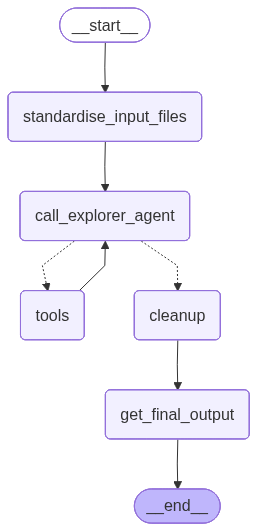

In [9]:
data_explorer.client

In [10]:
request = {
    "file_paths": ["dwc_data/masked-doi-10.34894-72gq4c/budburst_occurrence.csv"],
    "instruction": "Please tell me what are all unique values in the 'class' column."
}

In [11]:
data_explorer.client.invoke({"request": request}, {"recursion_limit": 25})

{'messages': [AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 42, 'prompt_tokens': 672, 'total_tokens': 714, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-4.1-mini-2025-04-14', 'system_fingerprint': 'fp_fef13761cf', 'id': 'chatcmpl-DU8er5lR2pmTwCznJZn4n5ffXQuGU', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--019d8659-4efb-7a00-8f72-9d0b35130ed9-0', tool_calls=[{'name': 'query_dataset', 'args': {'sql_query': "DESCRIBE SELECT * FROM '/tmp/massi_gbozksfo/data_0_budburst_occurrence.csv' LIMIT 5"}, 'id': 'call_GNvzWYGmyRKKhfkhpbYHG7HE', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 672, 'output_tokens': 42, 'total_tokens': 714, 'input_token_details